# Módulo 4 — Autocovariância, ACF e PACF

## Seção 5 — Interpretação conjunta da ACF e da PACF: padrões, identificação e limites

**Estado:** texto para revisão científica e pedagógica. **Pré-requisitos:** Módulo 4, Seções 1–4; modelos AR(1), AR(2) e MA(1) introdutórios. **Programação integrada:** Python 3, NumPy, Matplotlib e Statsmodels; todas as séries apresentadas são sintéticas.

**Fundamentação consultada:** Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, volume 1, 3ª ed., §5.2.5, pp. 138–139 (pp. 157–158 do PDF): propriedades da PACF de modelos AR, MA e ARMA. A discussão do catálogo de videoaulas sobre ACF e PACF, registros 44–54, orienta o percurso didático. **Complementações didáticas originais:** deduções dos padrões em AR(1) e MA(1), análise de situações ambíguas, implementação comparativa, interpretação cautelosa de bandas e exercícios. Esta seção **não** é uma apresentação completa de estimação ARIMA, reservada a conteúdo posterior.

### Objetivos

Relacionar ACF e PACF à estrutura do modelo; deduzir padrões típicos de AR e MA; compreender o significado de "corte" e "decaimento" na **população**; distinguir estimativas amostrais desses padrões ideais; interpretar gráficos e suas bandas com cautela; avaliar quando ACF e PACF não bastam para identificar um modelo.

### 1. Duas perguntas complementares

Para um processo fracamente estacionário com $\gamma(0)>0$, a autocorrelação teórica de defasagem $h$ é:

$$
\rho(h)=\frac{\gamma(h)}{\gamma(0)}.
$$

A ACF pergunta: **qual é a associação linear entre $Z_t$ e $Z_{t-h}$?** A PACF pergunta: **qual associação linear permanece após controlar $Z_{t-1},\ldots,Z_{t-h+1}$?**

No estudo de processos estacionários, essas funções oferecem pistas sobre uma representação autorregressiva ou de médias móveis. São resumos de **segunda ordem**; não caracterizam, em geral, toda a lei de probabilidade.

### 2. Modelo AR(1): ACF gradual e PACF com corte

Considere a solução causal estacionária

$$
Z_t=\phi Z_{t-1}+\varepsilon_t, \qquad |\phi|<1,
$$

com ruído branco de média zero e variância $\sigma^2>0$. Para a dedução das equações de covariância, $\varepsilon_t$ deve ser não correlacionado com $Z_{t-h}$ para $h\ge1$, propriedade satisfeita na construção causal usual a partir de inovações não correlacionadas.

Multiplicando a equação por $Z_{t-h}$ e tomando a esperança (a média é zero), encontramos, para $h\ge1$:

$$
\begin{aligned}
\gamma(h)&=\mathrm{Cov}(\phi Z_{t-1}+\varepsilon_t,Z_{t-h})\\
&=\phi\gamma(h-1).
\end{aligned}
$$

Da recorrência:

$$
\boxed{\rho(h)=\phi^{|h|}.}
$$

A ACF não se anula bruscamente: diminui geometricamente quando $|\phi|<1$. Se $\phi<0$, seus sinais alternam. A variância estacionária é $\gamma(0)=\sigma^2/(1-\phi^2)$.

**E a PACF?** Uma vez considerado $Z_{t-1}$, os valores mais antigos não acrescentam **informação linear** para prever $Z_t$ na equação acima. Assim:

$$
\alpha(1)=\phi,\qquad \alpha(h)=0\quad(h\ge2).
$$

O termo **corte após a defasagem 1** refere-se à PACF populacional; um gráfico amostral dificilmente exibirá zeros exatos em todas as outras defasagens.

### 3. Modelo MA(1): ACF com corte e PACF gradual

Considere

$$
Z_t=\varepsilon_t+\theta\varepsilon_{t-1},
$$

com inovações de média zero, variância $\sigma^2$ e covariância nula em defasagens não nulas. Por expansão:

$$
\begin{aligned}
\gamma(0)&=\mathrm{Var}(\varepsilon_t+\theta\varepsilon_{t-1})=(1+\theta^2)\sigma^2,\\
\gamma(1)&=\mathrm{Cov}(\varepsilon_t+\theta\varepsilon_{t-1},\varepsilon_{t-1}+\theta\varepsilon_{t-2})=\theta\sigma^2,\\
\gamma(h)&=0,\qquad |h|\ge2.
\end{aligned}
$$

Logo,

$$
\boxed{\rho(1)=\frac{\theta}{1+\theta^2},\qquad \rho(h)=0\ (|h|\ge2).}
$$

A **ACF** tem corte teórico após a defasagem 1. Mas a PACF de ordem 2 já pode ser diferente de zero:

$$
\begin{aligned}
\alpha(2)&=\frac{\rho(2)-\rho(1)^2}{1-\rho(1)^2}\\
&=-\frac{\rho(1)^2}{1-\rho(1)^2}.
\end{aligned}
$$

Se $\theta=0{,}6$, então $\rho(1)=0{,}6/1{,}36\approx0{,}44118$ e $\alpha(2)\approx-0{,}24170$. Note: **ACF zero na ordem 2 não implica PACF zero na mesma ordem**. Para o MA(1) invertível (por exemplo, $|\theta|<1$), a PACF tende a decair gradualmente.

### 4. Modelo AR(2) e o cuidado com padrões simplificados

Considere

$$
Z_t=\phi_1 Z_{t-1}+\phi_2 Z_{t-2}+\varepsilon_t.
$$

Sob a condição de existência de uma solução causal estacionária, a autocovariância obedece à recorrência:

$$
\gamma(h)=\phi_1\gamma(h-1)+\phi_2\gamma(h-2),\qquad h\ge2.
$$

Dessa equação podem surgir decaimentos por combinações de exponenciais, às vezes com oscilação amortecida. A PACF populacional tem $\alpha(h)=0$ para $h>2$, enquanto a ACF geralmente não apresenta corte finito. Dependendo dos parâmetros, o decaimento pode ser muito rápido, confundindo a leitura visual.

**Não se conclui uma ordem de modelo apenas contando barras que ultrapassam uma banda:** várias defasagens são examinadas, as estimativas são dependentes e os modelos podem produzir padrões próximos.

### 5. Quadro comparativo: o que esperar *teoricamente*

| Processo estacionário | ACF teórica | PACF teórica | Interpretação inicial |
|---|---|---|---|
| Ruído branco | Zero para $h\ne0$ | Zero para $h\ge1$ | Ausência de dependência **linear** em defasagens não nulas |
| AR($p$) causal estacionário | Decaimento, possivelmente oscilatório | Corte após $p$ | Ordem AR possível |
| MA($q$) | Corte após $q$ | Decaimento gradual, em casos usuais invertíveis | Ordem MA possível |
| ARMA($p,q$) estacionário/invertível | Em geral, decaimento | Em geral, decaimento | Exige investigação adicional |

A tabela expressa padrões típicos de uma família de modelos, **não** regras infalíveis para amostras finitas. Casos com parâmetros nulos, cancelamentos ou condições excepcionais podem produzir padrões distintos. ACF e PACF dizem respeito à associação linear, não à independência irrestrita.

### 6. Por que as bandas de aproximadamente $\pm1{,}96/\sqrt N$ exigem cautela?

Para ruído branco independente com condições regulares, a autocorrelação amostral em uma defasagem **fixa**, positiva, tem aproximadamente desvio padrão $1/\sqrt N$ em amostras grandes. Daí surge a heurística:

$$
\boxed{\text{limites aproximados}=\pm\frac{1{,}96}{\sqrt N}.}
$$

Ela é frequentemente desenhada para referência em gráficos. Porém:

- Não é uma banda simultânea para todas as defasagens; examinar muitas barras aumenta a chance de ultrapassagens ocasionais.
- Não deve ser interpretada como teste universal de independência ou como intervalo de confiança válido sob qualquer estrutura temporal.
- Em séries não estacionárias, padrões de ACF podem ser enganosos; as propriedades dependem do mecanismo gerador e das transformações usadas.
- A variabilidade da PACF estimada também depende do método e do modelo, sobretudo fora dos casos assintóticos simples.

Em uma análise científica, é necessário complementar a inspeção com hipóteses explícitas, avaliação de resíduos, plausibilidade do modelo e, quando for o objetivo, procedimentos de validação temporal.

### 7. Experimento integrado em Python

Simularemos quatro processos diferentes, usando uma semente fixa. A biblioteca `ArmaProcess` recebe polinômios com o sinal negativo dos coeficientes autorregressivos. Assim, o AR(2) $Z_t=0{,}6Z_{t-1}-0{,}25Z_{t-2}+\varepsilon_t$ é codificado como `[1, -0.6, 0.25]`. O parâmetro `burnin` descarta observações iniciais.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import acf, pacf

rng = np.random.default_rng(20261117)
n, K = 1200, 24

ar1 = ArmaProcess([1, -0.65], [1]).generate_sample(
    nsample=n, burnin=500, distrvs=rng.standard_normal
)
ar2 = ArmaProcess([1, -0.6, 0.25], [1]).generate_sample(
    nsample=n, burnin=500, distrvs=rng.standard_normal
)
ma1 = ArmaProcess([1], [1, 0.6]).generate_sample(
    nsample=n, burnin=500, distrvs=rng.standard_normal
)
ruido = rng.standard_normal(n)

series = {"Ruído branco": ruido, "AR(1)": ar1,
          "AR(2)": ar2, "MA(1)": ma1}

fig, axes = plt.subplots(4, 2, figsize=(12, 11), sharex=True)
for i, (nome, z) in enumerate(series.items()):
    estim_acf = acf(z, nlags=K, fft=True)[1:]
    estim_pacf = pacf(z, nlags=K, method="ywm")[1:]
    for j, valores in enumerate([estim_acf, estim_pacf]):
        ax = axes[i, j]
        h = np.arange(1, K + 1)
        ax.axhline(0, color="gray")
        ax.vlines(h, 0, valores)
        ax.scatter(h, valores, s=10)
        ax.axhline(1.96/np.sqrt(n), ls="--", color="gray")
        ax.axhline(-1.96/np.sqrt(n), ls="--", color="gray")
        ax.set_ylim(-0.45, 1.0)
        ax.set_ylabel(nome)
        ax.set_title("ACF" if j == 0 else "PACF")
        ax.grid(alpha=0.15)
        if i == 3:
            ax.set_xlabel("Defasagem")
plt.tight_layout()
plt.show()


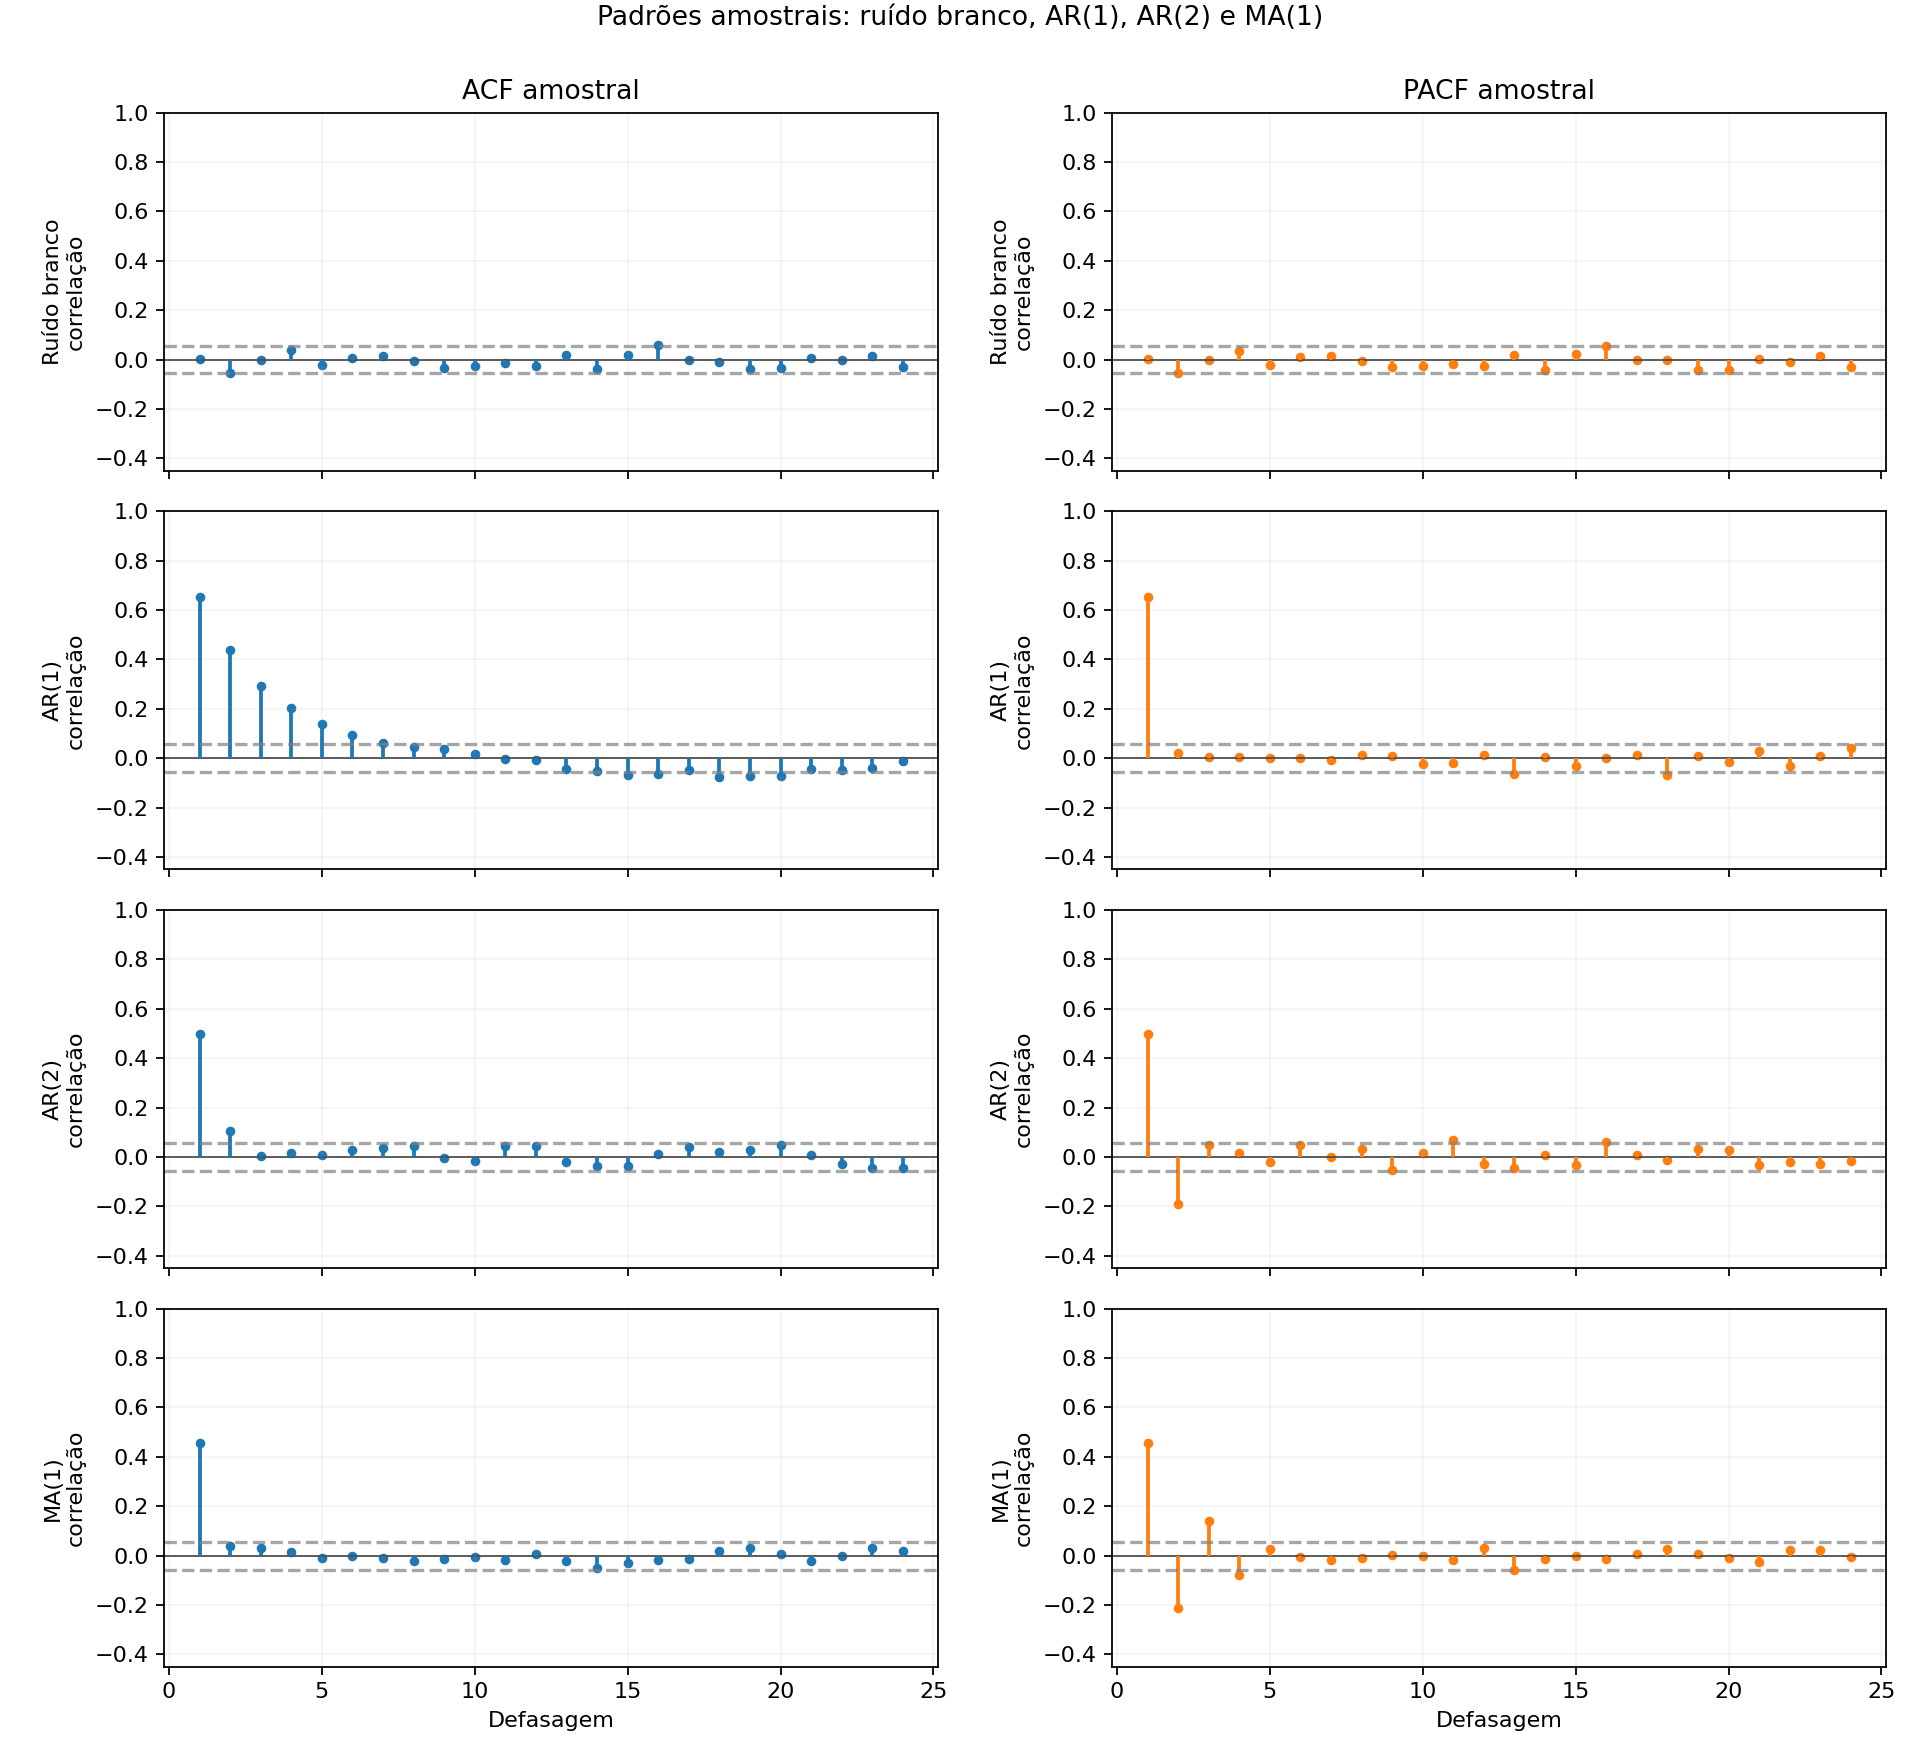

**Figura 1.** ACF e PACF amostrais de quatro modelos simulados com $N=1200$. Linhas tracejadas indicam $\pm1{,}96/\sqrt N$, **apenas como referência heurística**. O corte é propriedade da função **teórica**; barras fora da banda em defasagens posteriores podem ocorrer por erro amostral. A simulação ilustra os padrões, não os demonstra.

**Leitura guiada:** o AR(1) mostra correlação na primeira defasagem e uma ACF que decai; o AR(2) admite uma segunda PACF populacional não nula; o MA(1) apresenta ACF teórica zero após 1, embora as barras amostrais não sejam exatamente nulas; ruído branco gera oscilações ao redor de zero. Não conclua independência apenas porque as barras são pequenas.

### 8. Problema de identificação: uma única trajetória não informa tudo

A observação de uma ACF que decai lentamente pode corresponder a um AR quase persistente, a uma série com tendência ainda não removida ou a outros mecanismos. A comparação deve começar pela pergunta: *a hipótese de estacionariedade fraca é razoável para a série e para a escala analisada?* Se não for, padrões de ARMA estacionários não devem ser transferidos automaticamente.

Outro risco é confundir **boa explicação retrospectiva** com **capacidade de previsão**. ACF e PACF são ferramentas de análise e identificação preliminar, não uma validação fora da amostra. Quando modelos forem ajustados em módulos posteriores, seus resíduos e desempenho preditivo precisarão ser examinados separadamente.

### 9. Exercícios

1. **Dedução:** obtenha $\gamma(0)$ e $\gamma(1)$ do MA(1) expandindo cada produto antes de usar a hipótese de ruído branco.
2. **Interpretação:** explique por que a PACF de ordem 2 pode ser não nula mesmo quando $\rho(2)=0$.
3. **Matemática:** para AR(1) com $\phi=-0{,}5$, calcule $\rho(1),\rho(2),\rho(3)$ e indique o padrão de sinais.
4. **Python:** aumente o comprimento da simulação para 5.000 observações, mantendo a mesma semente, e compare a irregularidade das estimativas com $N=1200$.
5. **Reflexão científica:** um colega observa três barras além de uma banda pontual em 40 defasagens. Por que não pode concluir automaticamente que o processo não é ruído branco?
6. **Projeto:** proponha um pseudocódigo para avaliar ACF e PACF em uma série de precipitação que contém dias sem medição. Explique por que não se deve substituir indiscriminadamente ausências por zero antes de calcular correlações.

**Resposta selecionada (exercício 3):** $\rho(1)=-0{,}5$, $\rho(2)=0{,}25$, $\rho(3)=-0{,}125$. Os sinais alternam e o módulo decai geometricamente.

### Síntese e fontes

A ACF descreve associação linear total por defasagem; a PACF resume a associação linear residual após remover os instantes intermediários. Padrões de corte e decaimento ajudam a formular hipóteses de modelos, mas exigem estacionariedade apropriada, cuidado com as estimativas, diagnósticos adicionais e consciência dos limites de amostras finitas.

**Fonte acadêmica consultada:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: modelos lineares univariados*. v. 1, 3. ed. Blucher, 2018, §5.2.5, pp. 138–139. **Fonte pedagógica:** `mapeamento-conteudos-series-temporais.md`, registros sobre ACF/PACF e modelos AR/MA. **Complementações originais:** deduções específicas, experimento Python, interpretação metodológica e exercícios desta seção.